In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("E-Commerce Sales Analysis Project")
print("All libraries imported successfully!")

E-Commerce Sales Analysis Project
All libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving ecommerce_sales_1500.csv to ecommerce_sales_1500.csv


In [3]:
df = pd.read_csv("ecommerce_sales_1500.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
df.head()

,Order_ID,Order_Date,Customer_ID,Product,Category,Quantity,Unit_Price,Discount_Percent,Payment_Method,City
0,ORD01458,2025-01-01,CUST0063,Hoodie,Clothing,1,1143,10,UPI,Coimbatore
1,ORD01008,2025-01-01,CUST0006,Hoodie,Clothing,5,1717,5,Credit Card,Delhi
2,ORD00136,2025-01-01,CUST0011,Business Studies,Books,2,364,5,Credit Card,Mumbai
3,ORD00421,2025-01-02,CUST0064,Desk Lamp,Home & Kitchen,1,1595,0,UPI,Bengaluru
4,ORD00551,2025-01-02,CUST0211,Sneakers,Clothing,1,1852,15,UPI,Pune


In [5]:
df.shape

(1500, 10)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Order_ID          1500 non-null   object
 1   Order_Date        1500 non-null   object
 2   Customer_ID       1500 non-null   object
 3   Product           1500 non-null   object
 4   Category          1500 non-null   object
 5   Quantity          1500 non-null   int64 
 6   Unit_Price        1500 non-null   int64 
 7   Discount_Percent  1500 non-null   int64 
 8   Payment_Method    1500 non-null   object
 9   City              1500 non-null   object
dtypes: int64(3), object(7)
memory usage: 117.3+ KB


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df['Order_Date'] = pd.to_datetime(df['Order_Date'])

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Order_ID          1500 non-null   object        
 1   Order_Date        1500 non-null   datetime64[ns]
 2   Customer_ID       1500 non-null   object        
 3   Product           1500 non-null   object        
 4   Category          1500 non-null   object        
 5   Quantity          1500 non-null   int64         
 6   Unit_Price        1500 non-null   int64         
 7   Discount_Percent  1500 non-null   int64         
 8   Payment_Method    1500 non-null   object        
 9   City              1500 non-null   object        
dtypes: datetime64[ns](1), int64(3), object(6)
memory usage: 117.3+ KB


In [9]:
df.isnull().sum()

,0
Order_ID,0
Order_Date,0
Customer_ID,0
Product,0
Category,0
Quantity,0
Unit_Price,0
Discount_Percent,0
Payment_Method,0
City,0


In [11]:
df['Revenue'] = (
    df['Quantity'] *
    df['Unit_Price'] *
    (1 - df['Discount_Percent'] / 100)
)

In [12]:
df.head()

,Order_ID,Order_Date,Customer_ID,Product,Category,Quantity,Unit_Price,Discount_Percent,Payment_Method,City,Revenue
0,ORD01458,2025-01-01,CUST0063,Hoodie,Clothing,1,1143,10,UPI,Coimbatore,1028.70
1,ORD01008,2025-01-01,CUST0006,Hoodie,Clothing,5,1717,5,Credit Card,Delhi,8155.75
2,ORD00136,2025-01-01,CUST0011,Business Studies,Books,2,364,5,Credit Card,Mumbai,691.60
3,ORD00421,2025-01-02,CUST0064,Desk Lamp,Home & Kitchen,1,1595,0,UPI,Bengaluru,1595.00
4,ORD00551,2025-01-02,CUST0211,Sneakers,Clothing,1,1852,15,UPI,Pune,1574.20


In [13]:
total_revenue = df['Revenue'].sum()

print("Total Revenue: ₹", round(total_revenue, 2))

Total Revenue: ₹ 3909178.55


In [14]:
product_sales = df.groupby('Product')['Quantity'].sum()

product_sales = product_sales.sort_values(ascending=False)

print(product_sales)

Product
Desk Lamp                182
Bedsheet                 180
Jeans                    176
USB-C Cable              168
Sneakers                 161
Hoodie                   158
Wireless Mouse           158
T-Shirt                  156
Coffee Maker             154
Headphones               152
Water Bottle             151
Data Analytics Basics    146
Bluetooth Speaker        144
Science Encyclopedia     140
Python Programming       139
Backpack                 139
Cookware Set             139
Business Studies         128
Mystery Novel            125
Power Bank               121
Name: Quantity, dtype: int64


In [15]:
product_revenue = df.groupby('Product')['Revenue'].sum()

product_revenue = product_revenue.sort_values(ascending=False)

print(product_revenue)

Product
Coffee Maker             492493.10
Sneakers                 416889.55
Cookware Set             367154.55
Bluetooth Speaker        346680.45
Jeans                    300609.05
Headphones               263529.50
Bedsheet                 241107.85
Hoodie                   198437.00
Desk Lamp                191376.90
Power Bank               190545.60
Backpack                 156478.80
Science Encyclopedia     132259.40
Wireless Mouse           109783.30
Data Analytics Basics    103194.80
Python Programming        88309.20
T-Shirt                   87042.05
Water Bottle              66293.50
Business Studies          61958.05
USB-C Cable               54549.60
Mystery Novel             40486.30
Name: Revenue, dtype: float64


In [16]:
category_sales = df.groupby('Category')['Quantity'].sum()

category_sales = category_sales.sort_values(ascending=False)

print(category_sales)

Category
Home & Kitchen    806
Clothing          790
Electronics       743
Books             678
Name: Quantity, dtype: int64


In [17]:
category_revenue = df.groupby('Category')['Revenue'].sum()

category_revenue = category_revenue.sort_values(ascending=False)

print(category_revenue)

Category
Home & Kitchen    1358425.90
Clothing          1159456.45
Electronics        965088.45
Books              426207.75
Name: Revenue, dtype: float64


In [18]:
monthly_revenue = df.groupby(df['Order_Date'].dt.month)['Revenue'].sum()

print(monthly_revenue)

Order_Date
1     385075.80
2     300325.95
3     393124.15
4     288637.10
5     304733.35
6     341345.50
7     314416.35
8     369929.95
9     284224.45
10    302014.35
11    307090.30
12    318261.30
Name: Revenue, dtype: float64


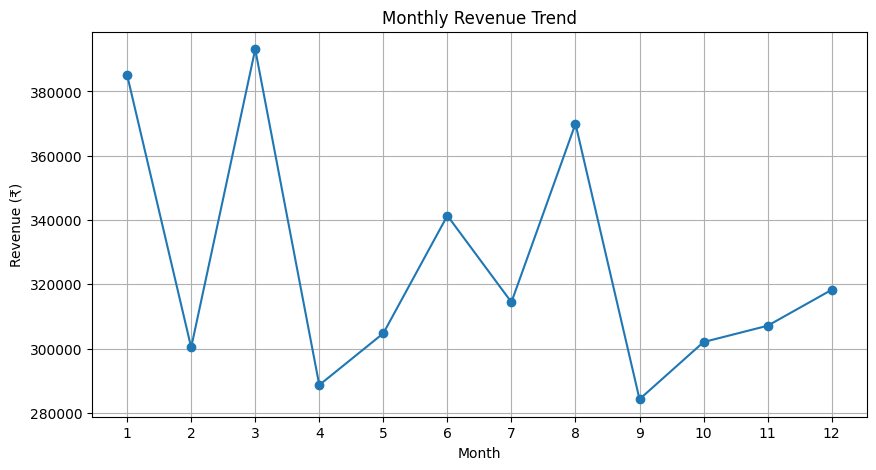

In [19]:
monthly_revenue.plot(
    kind='line',
    marker='o',
    figsize=(10, 5),
    title='Monthly Revenue Trend'
)

plt.xlabel('Month')
plt.ylabel('Revenue (₹)')
plt.xticks(range(1, 13))
plt.grid(True)
plt.show()

In [20]:
customer_revenue = df.groupby('Customer_ID')['Revenue'].sum()

top_customers = customer_revenue.sort_values(
    ascending=False
).head(10)

print(top_customers)

Customer_ID
CUST0336    51384.20
CUST0245    39012.05
CUST0255    37727.30
CUST0162    36007.75
CUST0101    35915.80
CUST0032    33635.50
CUST0044    33627.05
CUST0211    32731.90
CUST0083    29894.75
CUST0281    28963.30
Name: Revenue, dtype: float64


In [21]:
payment_analysis = df['Payment_Method'].value_counts()

print(payment_analysis)

Payment_Method
UPI                 625
Credit Card         342
Debit Card          254
Cash on Delivery    196
Net Banking          83
Name: count, dtype: int64


In [22]:
city_revenue = df.groupby('City')['Revenue'].sum()

city_revenue = city_revenue.sort_values(ascending=False)

print(city_revenue)

City
Delhi         486816.75
Hyderabad     442290.60
Bengaluru     408117.90
Kochi         405941.90
Coimbatore    402364.25
Pune          383090.40
Jaipur        376112.50
Kolkata       345821.25
Chennai       341319.45
Mumbai        317303.55
Name: Revenue, dtype: float64


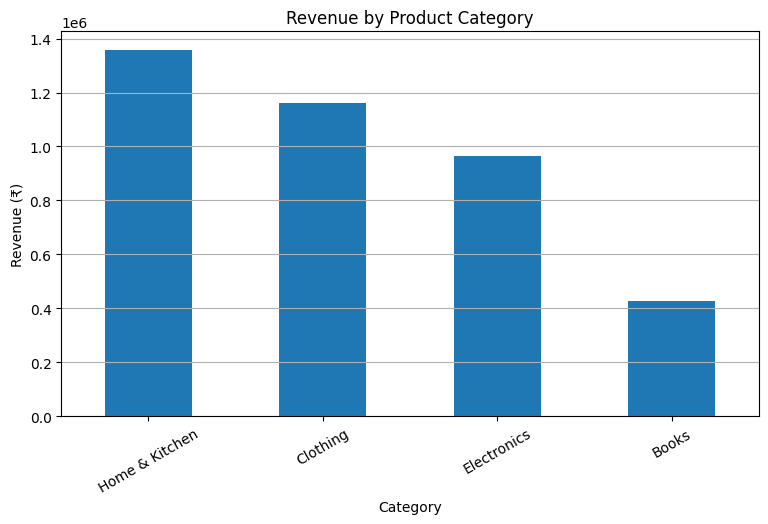

In [23]:
category_revenue.plot(
    kind='bar',
    figsize=(9, 5),
    title='Revenue by Product Category'
)

plt.xlabel('Category')
plt.ylabel('Revenue (₹)')
plt.xticks(rotation=30)
plt.grid(axis='y')
plt.show()

In [24]:
total_orders = df['Order_ID'].nunique()

average_order_value = total_revenue / total_orders

print("Total Orders:", total_orders)
print("Average Order Value: ₹", round(average_order_value, 2))

Total Orders: 1500
Average Order Value: ₹ 2606.12


In [25]:
total_quantity = df['Quantity'].sum()

print("Total Quantity Sold:", total_quantity)

Total Quantity Sold: 3017


In [26]:
average_quantity = df['Quantity'].mean()

print("Average Quantity per Order:", round(average_quantity, 2))

Average Quantity per Order: 2.01


In [27]:
highest_order = df.loc[df['Revenue'].idxmax()]

lowest_order = df.loc[df['Revenue'].idxmin()]

print("Highest Revenue Order:")
print(highest_order)

print("\nLowest Revenue Order:")
print(lowest_order)

Highest Revenue Order:
Order_ID                       ORD00112
Order_Date          2025-08-27 00:00:00
Customer_ID                    CUST0054
Product                    Coffee Maker
Category                 Home & Kitchen
Quantity                              5
Unit_Price                         4884
Discount_Percent                     20
Payment_Method               Debit Card
City                          Hyderabad
Revenue                         19536.0
Name: 1020, dtype: object

Lowest Revenue Order:
Order_ID                       ORD01376
Order_Date          2025-06-10 00:00:00
Customer_ID                    CUST0328
Product                     USB-C Cable
Category                    Electronics
Quantity                              1
Unit_Price                          214
Discount_Percent                     15
Payment_Method               Debit Card
City                            Chennai
Revenue                           181.9
Name: 697, dtype: object


In [28]:
category_percentage = (
    category_revenue / total_revenue
) * 100

print(category_percentage.round(2))


Category
Home & Kitchen    34.75
Clothing          29.66
Electronics       24.69
Books             10.90
Name: Revenue, dtype: float64


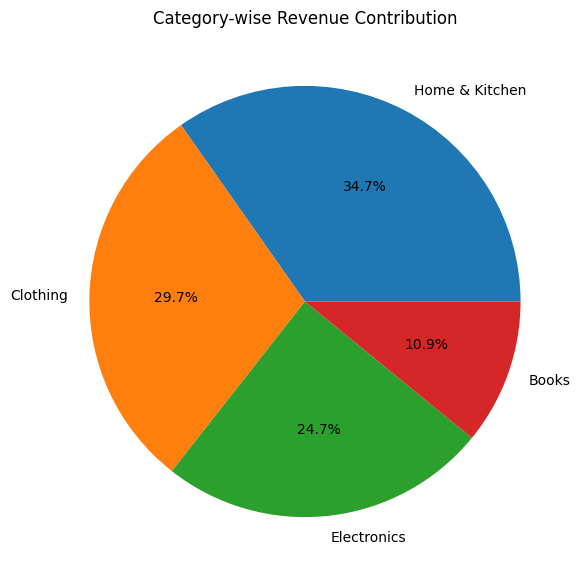

In [29]:
category_percentage.plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(7, 7),
    title='Category-wise Revenue Contribution'
)

plt.ylabel('')
plt.show()

In [30]:
discount_analysis = df.groupby('Discount_Percent')['Revenue'].mean()

print(discount_analysis.round(2))

Discount_Percent
0     2600.92
5     2465.34
10    2691.93
15    2518.11
20    2957.06
Name: Revenue, dtype: float64


In [31]:
payment_revenue = df.groupby('Payment_Method')['Revenue'].sum()

payment_revenue = payment_revenue.sort_values(ascending=False)

print(payment_revenue)

Payment_Method
UPI                 1565548.00
Credit Card          978856.85
Debit Card           631448.20
Cash on Delivery     510550.45
Net Banking          222775.05
Name: Revenue, dtype: float64


In [32]:
city_category = df.groupby(
    ['City', 'Category']
)['Quantity'].sum()

print(city_category)

City        Category      
Bengaluru   Books              82
            Clothing           96
            Electronics        72
            Home & Kitchen     89
Chennai     Books              57
            Clothing           77
            Electronics        81
            Home & Kitchen     66
Coimbatore  Books              62
            Clothing           69
            Electronics        61
            Home & Kitchen    104
Delhi       Books              80
            Clothing           82
            Electronics        76
            Home & Kitchen     94
Hyderabad   Books              65
            Clothing           97
            Electronics        64
            Home & Kitchen     84
Jaipur      Books              69
            Clothing           73
            Electronics        96
            Home & Kitchen     62
Kochi       Books              88
            Clothing           69
            Electronics        76
            Home & Kitchen     89
Kolkata     Books    

In [33]:
city_category_table = city_category.unstack()

print(city_category_table)

Category    Books  Clothing  Electronics  Home & Kitchen
City                                                    
Bengaluru      82        96           72              89
Chennai        57        77           81              66
Coimbatore     62        69           61             104
Delhi          80        82           76              94
Hyderabad      65        97           64              84
Jaipur         69        73           96              62
Kochi          88        69           76              89
Kolkata        58        73           65              83
Mumbai         56        84           74              43
Pune           61        70           78              92


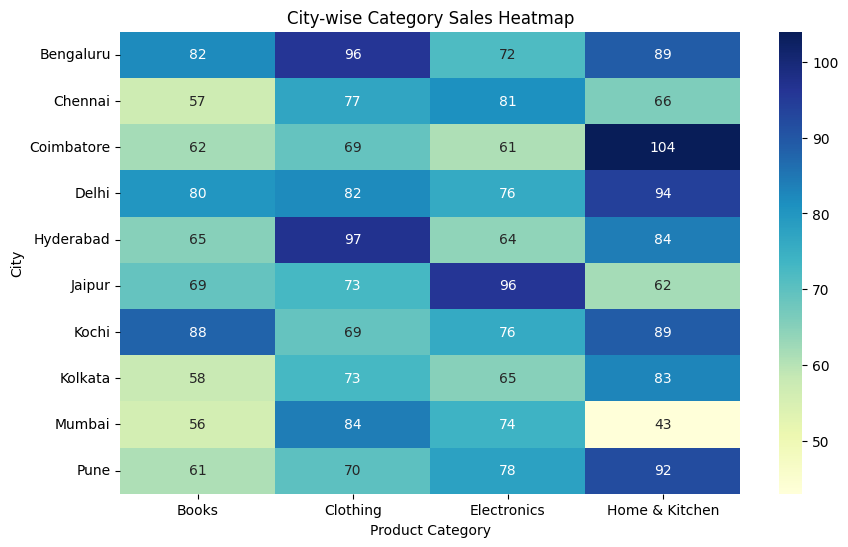

In [34]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    city_category_table,
    annot=True,
    cmap='YlGnBu',
    fmt='d'
)

plt.title('City-wise Category Sales Heatmap')
plt.xlabel('Product Category')
plt.ylabel('City')
plt.show()

In [35]:
print("========== PROJECT SUMMARY ==========")

print("Total Orders:", df['Order_ID'].nunique())

print("Total Quantity Sold:", df['Quantity'].sum())

print("Total Revenue: ₹", round(df['Revenue'].sum(), 2))

print("Average Order Value: ₹", round(df['Revenue'].mean(), 2))

print("Best Selling Product:",
      product_sales.idxmax())

print("Highest Revenue Product:",
      product_revenue.idxmax())

print("Top Revenue Category:",
      category_revenue.idxmax())

print("Top Revenue City:",
      city_revenue.idxmax())

print("Most Used Payment Method:",
      payment_analysis.idxmax())

print("Highest Revenue Month:",
      monthly_revenue.idxmax())

========== PROJECT SUMMARY ==========
Total Orders: 1500
Total Quantity Sold: 3017
Total Revenue: ₹ 3909178.55
Average Order Value: ₹ 2606.12
Best Selling Product: Desk Lamp
Highest Revenue Product: Coffee Maker
Top Revenue Category: Home & Kitchen
Top Revenue City: Delhi
Most Used Payment Method: UPI
Highest Revenue Month: 3


In [36]:
print("========== E-COMMERCE PROJECT SUMMARY ==========")

print("\n--- OVERALL PERFORMANCE ---")

print("Total Orders:", df['Order_ID'].nunique())

print("Total Quantity Sold:", df['Quantity'].sum())

print("Total Revenue: ₹", round(total_revenue, 2))

print("Average Order Value: ₹", round(average_order_value, 2))


print("\n--- PRODUCT ANALYSIS ---")

print("Best Selling Product:", product_sales.idxmax())

print("Quantity Sold:", product_sales.max(), "units")

print("Best Selling Product Revenue: ₹",
      round(product_revenue[product_sales.idxmax()], 2))

print("Highest Revenue Product:", product_revenue.idxmax())

print("Highest Product Revenue: ₹",
      round(product_revenue.max(), 2))


print("\n--- CATEGORY ANALYSIS ---")

print("Top Revenue Category:", category_revenue.idxmax())

print("Category Revenue: ₹",
      round(category_revenue.max(), 2))


print("\n--- CITY ANALYSIS ---")

print("Top Revenue City:", city_revenue.idxmax())

print("City Revenue: ₹",
      round(city_revenue.max(), 2))


print("\n--- PAYMENT ANALYSIS ---")

print("Most Used Payment Method:", payment_analysis.idxmax())

print("Number of Transactions:", payment_analysis.max())


print("\n--- MONTHLY ANALYSIS ---")

print("Highest Revenue Month:",
      monthly_revenue.idxmax())

print("Monthly Revenue: ₹",
      round(monthly_revenue.max(), 2))

========== E-COMMERCE PROJECT SUMMARY ==========

--- OVERALL PERFORMANCE ---
Total Orders: 1500
Total Quantity Sold: 3017
Total Revenue: ₹ 3909178.55
Average Order Value: ₹ 2606.12

--- PRODUCT ANALYSIS ---
Best Selling Product: Desk Lamp
Quantity Sold: 182 units
Best Selling Product Revenue: ₹ 191376.9
Highest Revenue Product: Coffee Maker
Highest Product Revenue: ₹ 492493.1

--- CATEGORY ANALYSIS ---
Top Revenue Category: Home & Kitchen
Category Revenue: ₹ 1358425.9

--- CITY ANALYSIS ---
Top Revenue City: Delhi
City Revenue: ₹ 486816.75

--- PAYMENT ANALYSIS ---
Most Used Payment Method: UPI
Number of Transactions: 625

--- MONTHLY ANALYSIS ---
Highest Revenue Month: 3
Monthly Revenue: ₹ 393124.15
